<a href="https://colab.research.google.com/github/Yaqiao-chi-helen/Forecasting-team4/blob/main/notebooks/Model_Development_XGBoost_LSTM_newest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XGBoost Model - Bhumika

In [133]:
import pandas as pd


In [134]:
df = pd.read_csv('/content/PJME_hourly_cleaned.csv')

In [135]:
df.head()


,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


In [136]:
df.shape

(145392, 2)

In [137]:
df.columns

Index(['Datetime', 'PJME_MW'], dtype='object')

In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145392 entries, 0 to 145391
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145392 non-null  object 
 1   PJME_MW   145392 non-null  float64
dtypes: float64(1), object(1)
memory usage: 2.2+ MB


In [139]:
df.isnull().sum()

,0
Datetime,0
PJME_MW,0


In [140]:
df.duplicated().sum()

np.int64(0)

In [141]:
df.describe()

,PJME_MW
count,145392.000000
mean,32078.930711
std,6464.279302
min,14544.000000
25%,27571.000000
50%,31420.000000
75%,35647.000000
max,62009.000000


In [142]:
df['Datetime'] = pd.to_datetime(df['Datetime'])

In [143]:
df['Datetime'] = pd.to_datetime(df['Datetime'], dayfirst=True)

In [144]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145392 entries, 0 to 145391
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145392 non-null  datetime64[ns]
 1   PJME_MW   145392 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.2 MB


In [145]:
df['Datetime'].head()

,Datetime
0,2002-01-01 01:00:00
1,2002-01-01 02:00:00
2,2002-01-01 03:00:00
3,2002-01-01 04:00:00
4,2002-01-01 05:00:00


In [146]:
print("Start date:", df['Datetime'].min())
print("End date:", df['Datetime'].max())

Start date: 2002-01-01 01:00:00
End date: 2018-08-03 00:00:00


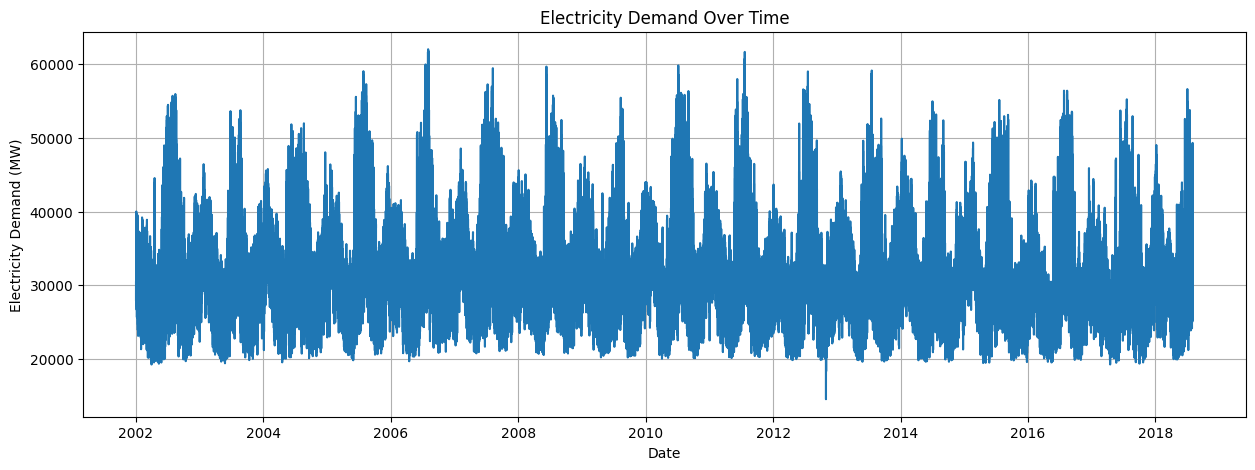

In [147]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(df['Datetime'], df['PJME_MW'])

plt.title('Electricity Demand Over Time')
plt.xlabel('Date')
plt.ylabel('Electricity Demand (MW)')

plt.grid(True)
plt.show()

In [148]:
df['Hour'] = df['Datetime'].dt.hour

In [149]:
df[['Datetime', 'Hour']].head(10)

,Datetime,Hour
0,2002-01-01 01:00:00,1
1,2002-01-01 02:00:00,2
2,2002-01-01 03:00:00,3
3,2002-01-01 04:00:00,4
4,2002-01-01 05:00:00,5
5,2002-01-01 06:00:00,6
6,2002-01-01 07:00:00,7
7,2002-01-01 08:00:00,8
8,2002-01-01 09:00:00,9
9,2002-01-01 10:00:00,10


In [150]:
df['Day'] = df['Datetime'].dt.day

In [151]:
df[['Datetime', 'Hour', 'Day']].head(10)

,Datetime,Hour,Day
0,2002-01-01 01:00:00,1,1
1,2002-01-01 02:00:00,2,1
2,2002-01-01 03:00:00,3,1
3,2002-01-01 04:00:00,4,1
4,2002-01-01 05:00:00,5,1
5,2002-01-01 06:00:00,6,1
6,2002-01-01 07:00:00,7,1
7,2002-01-01 08:00:00,8,1
8,2002-01-01 09:00:00,9,1
9,2002-01-01 10:00:00,10,1


In [152]:
df['Month'] = df['Datetime'].dt.month

In [153]:
df[['Datetime', 'Hour', 'Day', 'Month']].head(10)

,Datetime,Hour,Day,Month
0,2002-01-01 01:00:00,1,1,1
1,2002-01-01 02:00:00,2,1,1
2,2002-01-01 03:00:00,3,1,1
3,2002-01-01 04:00:00,4,1,1
4,2002-01-01 05:00:00,5,1,1
5,2002-01-01 06:00:00,6,1,1
6,2002-01-01 07:00:00,7,1,1
7,2002-01-01 08:00:00,8,1,1
8,2002-01-01 09:00:00,9,1,1
9,2002-01-01 10:00:00,10,1,1


In [154]:
df['DayOfWeek'] = df['Datetime'].dt.dayofweek

In [155]:
df[['Datetime', 'DayOfWeek']].head(10)

,Datetime,DayOfWeek
0,2002-01-01 01:00:00,1
1,2002-01-01 02:00:00,1
2,2002-01-01 03:00:00,1
3,2002-01-01 04:00:00,1
4,2002-01-01 05:00:00,1
5,2002-01-01 06:00:00,1
6,2002-01-01 07:00:00,1
7,2002-01-01 08:00:00,1
8,2002-01-01 09:00:00,1
9,2002-01-01 10:00:00,1


In [156]:
print("hello world")

hello world


In [157]:
df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)

In [158]:
df.head(10)

,Datetime,PJME_MW,Hour,Day,Month,DayOfWeek,IsWeekend
0,2002-01-01 01:00:00,30393.0,1,1,1,1,0
1,2002-01-01 02:00:00,29265.0,2,1,1,1,0
2,2002-01-01 03:00:00,28357.0,3,1,1,1,0
3,2002-01-01 04:00:00,27899.0,4,1,1,1,0
4,2002-01-01 05:00:00,28057.0,5,1,1,1,0
5,2002-01-01 06:00:00,28654.0,6,1,1,1,0
6,2002-01-01 07:00:00,29308.0,7,1,1,1,0
7,2002-01-01 08:00:00,29595.0,8,1,1,1,0
8,2002-01-01 09:00:00,29943.0,9,1,1,1,0
9,2002-01-01 10:00:00,30692.0,10,1,1,1,0


In [159]:
df[['Datetime', 'PJME_MW', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsWeekend']].head(10)

,Datetime,PJME_MW,Hour,Day,Month,DayOfWeek,IsWeekend
0,2002-01-01 01:00:00,30393.0,1,1,1,1,0
1,2002-01-01 02:00:00,29265.0,2,1,1,1,0
2,2002-01-01 03:00:00,28357.0,3,1,1,1,0
3,2002-01-01 04:00:00,27899.0,4,1,1,1,0
4,2002-01-01 05:00:00,28057.0,5,1,1,1,0
5,2002-01-01 06:00:00,28654.0,6,1,1,1,0
6,2002-01-01 07:00:00,29308.0,7,1,1,1,0
7,2002-01-01 08:00:00,29595.0,8,1,1,1,0
8,2002-01-01 09:00:00,29943.0,9,1,1,1,0
9,2002-01-01 10:00:00,30692.0,10,1,1,1,0


In [160]:
df['Lag_1h'] = df['PJME_MW'].shift(1)

In [161]:
df[['Datetime', 'PJME_MW', 'Lag_1h']].head(10)

,Datetime,PJME_MW,Lag_1h
0,2002-01-01 01:00:00,30393.0,NaN
1,2002-01-01 02:00:00,29265.0,30393.0
2,2002-01-01 03:00:00,28357.0,29265.0
3,2002-01-01 04:00:00,27899.0,28357.0
4,2002-01-01 05:00:00,28057.0,27899.0
5,2002-01-01 06:00:00,28654.0,28057.0
6,2002-01-01 07:00:00,29308.0,28654.0
7,2002-01-01 08:00:00,29595.0,29308.0
8,2002-01-01 09:00:00,29943.0,29595.0
9,2002-01-01 10:00:00,30692.0,29943.0


In [162]:
df['Lag_24h'] = df['PJME_MW'].shift(24)

In [163]:
df['Lag_168h'] = df['PJME_MW'].shift(168)

In [164]:
df[['Datetime', 'PJME_MW', 'Lag_1h', 'Lag_24h', 'Lag_168h']].head(180)

,Datetime,PJME_MW,Lag_1h,Lag_24h,Lag_168h
0,2002-01-01 01:00:00,30393.0,NaN,NaN,NaN
1,2002-01-01 02:00:00,29265.0,30393.0,NaN,NaN
2,2002-01-01 03:00:00,28357.0,29265.0,NaN,NaN
3,2002-01-01 04:00:00,27899.0,28357.0,NaN,NaN
4,2002-01-01 05:00:00,28057.0,27899.0,NaN,NaN
...,...,...,...,...,...
175,2002-01-08 08:00:00,37841.0,35335.0,34678.0,29595.0
176,2002-01-08 09:00:00,37417.0,37841.0,35349.0,29943.0
177,2002-01-08 10:00:00,36824.0,37417.0,35542.0,30692.0
178,2002-01-08 11:00:00,36504.0,36824.0,35857.0,31395.0


In [165]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [166]:
df.isnull().sum()

,0
Datetime,0
PJME_MW,0
Hour,0
Day,0
Month,0
DayOfWeek,0
IsWeekend,0
Lag_1h,1
Lag_24h,24
Lag_168h,168


In [167]:
df = df.dropna().reset_index(drop=True)

In [168]:
df.shape

(145224, 10)

In [169]:
df.isnull().sum()

,0
Datetime,0
PJME_MW,0
Hour,0
Day,0
Month,0
DayOfWeek,0
IsWeekend,0
Lag_1h,0
Lag_24h,0
Lag_168h,0


In [170]:
df.isnull().sum()

,0
Datetime,0
PJME_MW,0
Hour,0
Day,0
Month,0
DayOfWeek,0
IsWeekend,0
Lag_1h,0
Lag_24h,0
Lag_168h,0


In [171]:
df = df.dropna().reset_index(drop=True)

In [172]:
df.shape

(145224, 10)

In [173]:
train_size = int(len(df) * 0.8)

train = df.iloc[:train_size].copy()
test = df.iloc[train_size:].copy()

print("Training set:", train.shape)
print("Testing set:", test.shape)

Training set: (116179, 10)
Testing set: (29045, 10)


In [174]:
features = [
    'Hour',
    'Day',
    'Month',
    'DayOfWeek',
    'IsWeekend',
    'Lag_1h',
    'Lag_24h',
    'Lag_168h'
]

X_train = train[features]
y_train = train['PJME_MW']

X_test = test[features]
y_test = test['PJME_MW']

In [175]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [176]:
from tensorflow import keras

print("Keras is ready!")

Keras is ready!


In [177]:
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [178]:
from xgboost import XGBRegressor

In [179]:
print("XGBoost is ready!")

XGBoost is ready!


In [180]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)

In [181]:
print(X_train.dtypes)

Hour           int32
Day            int32
Month          int32
DayOfWeek      int32
IsWeekend      int64
Lag_1h       float64
Lag_24h      float64
Lag_168h     float64
dtype: object


In [182]:
X_train.head()

,Hour,Day,Month,DayOfWeek,IsWeekend,Lag_1h,Lag_24h,Lag_168h
0,1,8,1,1,0,31187.0,26862.0,30393.0
1,2,8,1,1,0,29445.0,25976.0,29265.0
2,3,8,1,1,0,28670.0,25641.0,28357.0
3,4,8,1,1,0,28375.0,25666.0,27899.0
4,5,8,1,1,0,28542.0,26328.0,28057.0


In [183]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42
)


In [184]:
print(X_train.dtypes)

Hour           int32
Day            int32
Month          int32
DayOfWeek      int32
IsWeekend      int64
Lag_1h       float64
Lag_24h      float64
Lag_168h     float64
dtype: object


In [185]:
X_train.head()

,Hour,Day,Month,DayOfWeek,IsWeekend,Lag_1h,Lag_24h,Lag_168h
0,1,8,1,1,0,31187.0,26862.0,30393.0
1,2,8,1,1,0,29445.0,25976.0,29265.0
2,3,8,1,1,0,28670.0,25641.0,28357.0
3,4,8,1,1,0,28375.0,25666.0,27899.0
4,5,8,1,1,0,28542.0,26328.0,28057.0


In [186]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (116179, 8)
y_train: (116179,)
X_test: (29045, 8)
y_test: (29045,)


In [187]:
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [188]:
y_pred = xgb_model.predict(X_test)

In [189]:
print(y_pred[:10])

[29847.867 30312.447 29504.426 27647.617 25362.646 23720.484 22694.986
 22248.383 22141.889 22181.967]


In [190]:
print("Predictions:", len(y_pred))
print("Actual values:", len(y_test))

Predictions: 29045
Actual values: 29045


In [191]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MAE: 335.78131569816236
RMSE: 451.24697253972664
MAPE: 1.0660224788330375 %


In [192]:
baseline_results = pd.DataFrame({
    'Model': ['XGBoost Baseline'],
    'MAE': [mae],
    'RMSE': [rmse],
    'MAPE (%)': [mape]
})

baseline_results

,Model,MAE,RMSE,MAPE (%)
0,XGBoost Baseline,335.781316,451.246973,1.066022


## XGBoost Baseline Results

The XGBoost model was trained using the engineered time-based and lag features. The dataset was split chronologically into 80% training data and 20% testing data to preserve the time-series structure.

The model was evaluated using Mean Absolute Error (MAE), Root Mean Square Error (RMSE), and Mean Absolute Percentage Error (MAPE).

The XGBoost baseline achieved an MAE of 335.78 MW, an RMSE of 451.25 MW, and a MAPE of 1.066%.

These results provide a baseline for comparison with the LSTM model and the proposed hybrid LSTM-XGBoost model.

## LSTM Model - Yaqiao (Helen)

In [193]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train[['PJME_MW']])
test_scaled = scaler.transform(test[['PJME_MW']])

print("Train scaled shape:", train_scaled.shape)
print("Test scaled shape:", test_scaled.shape)

Train scaled shape: (116179, 1)
Test scaled shape: (29045, 1)


In [194]:
def create_sequences(data, window_size=24):
  X, y = [], []
  for i in range(len(data) - window_size):
    X.append(data[i:i+window_size])
    y.append(data[i+window_size])
  return np.array(X), np.array(y)

window_size = 168

X_train_lstm, y_train_lstm = create_sequences(train_scaled, window_size)
X_test_lstm, y_test_lstm = create_sequences(test_scaled, window_size)

print("X_train_lstm shape:", X_train_lstm.shape)
print("y_train_lstm shape:", y_train_lstm.shape)
print("X_test_lstm shape:", X_test_lstm.shape)
print("y_test_lstm shape:", y_test_lstm.shape)

X_train_lstm shape: (116011, 168, 1)
y_train_lstm shape: (116011, 1)
X_test_lstm shape: (28877, 168, 1)
y_test_lstm shape: (28877, 1)


## Hyperparameter Tuning - LSTM Yaqiao

In [195]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error

tf.random.set_seed(42); np.random.seed(42)

def build_lstm(units, w, dropout=0.0):
    m = models.Sequential([layers.Input(shape=(w, 1)), layers.LSTM(units)])
    if dropout: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(32, activation='relu')); m.add(layers.Dense(1))
    m.compile(optimizer='adam', loss='mse')
    return m

def val_mae(units, w):
    X_tr, y_tr = create_sequences(train_scaled, window_size=w)
    n_val = int(len(X_tr) * 0.1)                 # last 10% of train = validation (chronological)
    X_fit, y_fit, X_val, y_val = X_tr[:-n_val], y_tr[:-n_val], X_tr[-n_val:], y_tr[-n_val:]
    m = build_lstm(units, w)
    m.fit(X_fit, y_fit, validation_data=(X_val, y_val), epochs=10, batch_size=64, verbose=0,
          callbacks=[EarlyStopping(patience=3, restore_best_weights=True)])
    pred = scaler.inverse_transform(m.predict(X_val, verbose=0))
    return mean_absolute_error(scaler.inverse_transform(y_val.reshape(-1, 1)), pred)

def val_mae_of(model, w):
    X_tr, y_tr = create_sequences(train_scaled, window_size=w)
    n_val = int(len(X_tr) * 0.1)
    pred = scaler.inverse_transform(model.predict(X_tr[-n_val:], verbose=0))
    return mean_absolute_error(scaler.inverse_transform(y_tr[-n_val:]), pred)

results = []
for u in [32, 64, 128]:                          # Step 1: compare units, window fixed at 24
    print(f"Training: window=24, units={u}")
    results.append({'Window': 24, 'Units': u, 'Validation MAE (MW)': val_mae(u, 24)})

best_u = min(results, key=lambda r: r['Validation MAE (MW)'])['Units']

for w in [48, 168]:                              # Step 2: compare window, using best units
    print(f"Training: window={w}, units={best_u}")
    results.append({'Window': w, 'Units': best_u, 'Validation MAE (MW)': val_mae(best_u, w)})

tuning_df = pd.DataFrame(results).round(2)
tuning_df

Training: window=24, units=32
Training: window=24, units=64
Training: window=24, units=128
Training: window=48, units=64
Training: window=168, units=64


,Window,Units,Validation MAE (MW)
0,24,32,323.56
1,24,64,312.01
2,24,128,354.65
3,48,64,332.16
4,168,64,250.01


**Tuning results.** Units were compared with the window fixed at 24 hours, then the window length was compared using the best number of units. Selection was based on validation MAE (last 10% of the training period), not the test set.

- 64 units gave the lowest validation MAE with a 24-hour window (312.01 MW); 32 units (323.56 MW) and 128 units (354.65 MW) performed worse.
- A 168-hour (one-week) window gave the lowest validation MAE overall (250.01 MW), compared with 332.16 MW for a 48-hour window.
- Final setting: 64 units, window = 168. An earlier run with different random initialisation selected the same configuration, which suggests the choice is robust, although individual values varied between runs.

In [217]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)              # resets Python, NumPy and TensorFlow seeds
tf.config.experimental.enable_op_determinism()  # makes GPU operations deterministic

lstm_model = models.Sequential([
    layers.Input(shape=(window_size, 1)),
    layers.LSTM(64),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.summary()



Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_21 (LSTM)                  │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [218]:
import time

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "lstm_checkpoint.keras", save_best_only=True, monitor='val_loss'
)
early_stop = tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)

start = time.time()
history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    validation_split=0.1,
    epochs=20,
    batch_size=64,
    callbacks=[checkpoint, early_stop]
)
train_minutes = (time.time() - start) / 60
print(f"Training time: {train_minutes:.1f} minutes")

Epoch 1/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.0019 - val_loss: 2.4906e-04
Epoch 2/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 2.0103e-04 - val_loss: 1.3641e-04
Epoch 3/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 1.3249e-04 - val_loss: 1.1817e-04
Epoch 4/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 1.1422e-04 - val_loss: 1.0148e-04
Epoch 5/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 1.0557e-04 - val_loss: 1.1387e-04
Epoch 6/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 9.6153e-05 - val_loss: 9.3501e-05
Epoch 7/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 8.7459e-05 - val_loss: 8.7586e-05
Epoch 8/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 7.8495e-05 - val_loss: 7.7538e-05
Epoch 9/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 7.1948e-05 - val_loss: 8.4480e-05
Epoch 10/20
1632/1632 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - loss: 6.6642e-05 - val_loss: 8.2607e-05
Epoch 11/20
1632/1632 ━

In [219]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

predictions_scaled = lstm_model.predict(X_test_lstm)

predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test_lstm)

mae_lstm = mean_absolute_error(y_test_actual, predictions)
rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, predictions))
mape_lstm = np.mean(np.abs((y_test_actual - predictions) / y_test_actual)) * 100

print(f"LSTM - MAE: {mae_lstm:.2f} MW, RMSE: {rmse_lstm:.2f} MW, MAPE: {mape_lstm:.3f}%")

903/903 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
LSTM - MAE: 237.83 MW, RMSE: 324.96 MW, MAPE: 0.769%


In [220]:
from tensorflow.keras.callbacks import EarlyStopping


tf.random.set_seed(42)
X168, y168 = create_sequences(train_scaled, window_size=168)
model_168 = build_lstm(64, 168, dropout=0.2)
model_168.fit(X168, y168, validation_split=0.1, epochs=20, batch_size=64, verbose=0,
              callbacks=[EarlyStopping(patience=3, restore_best_weights=True)])
val_168 = val_mae_of(model_168, 168)

# Same final settings, window 24
tf.random.set_seed(42)
X24, y24 = create_sequences(train_scaled, window_size=24)
model_24 = build_lstm(64, 24, dropout=0.2)
model_24.fit(X24, y24, validation_split=0.1, epochs=20, batch_size=64, verbose=0,
             callbacks=[EarlyStopping(patience=3, restore_best_weights=True)])
val_24 = val_mae_of(model_24, 24)

print(f"Validation MAE - window 168 + dropout: {val_168:.2f} MW")
print(f"Validation MAE - window 24  + dropout: {val_24:.2f} MW")

Validation MAE - window 168 + dropout: 341.85 MW
Validation MAE - window 24  + dropout: 412.97 MW


In [221]:
print(f"Final model validation MAE: {val_mae_of(lstm_model, 168):.2f} MW")

Final model validation MAE: 219.24 MW


**Dropout check.** Using the final training settings (20 epochs, early stopping), window 168 again outperformed window 24 on validation data (341.85 vs 412.97 MW), so window 168 was kept. However, dropout (0.2) clearly hurt performance: with identical settings, the final model without dropout reached a validation MAE of 219.24 MW, compared with 341.85 MW with dropout. Given the small model (about 19k parameters) and large training set (about 116k sequences), overfitting was not a concern, so dropout was not retained. Final configuration: 64 units, window 168, no dropout, early stopping.

In [222]:
comparison_results = pd.DataFrame({
    'Model': ['XGBoost Baseline', 'LSTM'],
    'MAE': [mae, mae_lstm],
    'RMSE': [rmse, rmse_lstm],
    'MAPE (%)': [mape, mape_lstm]
})

comparison_results

,Model,MAE,RMSE,MAPE (%)
0,XGBoost Baseline,335.781316,451.246973,1.066022
1,LSTM,237.832509,324.961193,0.769006


## Hybrid Weights (validation-based) - Helen

In [223]:
from sklearn.base import clone

# Same validation period for both models: last 10% of the training data
n_val = int((len(train) - window_size) * 0.1)

# XGBoost: retrain a copy WITHOUT the validation period, then evaluate on it
xgb_val_model = clone(xgb_model)
xgb_val_model.fit(X_train.iloc[:-n_val], y_train.iloc[:-n_val])
mae_xgb_val = mean_absolute_error(y_train.iloc[-n_val:], xgb_val_model.predict(X_train.iloc[-n_val:]))

# LSTM: validation MAE on the same period
mae_lstm_val = val_mae_of(lstm_model, window_size)

# Error-reciprocal weights from VALIDATION error (not test)
weight_lstm = (1 / mae_lstm_val) / (1 / mae_lstm_val + 1 / mae_xgb_val)
weight_xgb = 1 - weight_lstm

print(f"Validation MAE - XGBoost: {mae_xgb_val:.2f} MW, LSTM: {mae_lstm_val:.2f} MW")
print(f"LSTM weight: {weight_lstm:.3f}, XGBoost weight: {weight_xgb:.3f}")

Validation MAE - XGBoost: 320.09 MW, LSTM: 219.24 MW
LSTM weight: 0.593, XGBoost weight: 0.407


In [224]:
y_pred_xgb_aligned = y_pred[window_size:]
y_test_common = y_test_actual.flatten()

hybrid_pred = weight_lstm * predictions.flatten() + weight_xgb * y_pred_xgb_aligned

mae_hybrid = mean_absolute_error(y_test_common, hybrid_pred)
rmse_hybrid = np.sqrt(mean_squared_error(y_test_common, hybrid_pred))
mape_hybrid = np.mean(np.abs((y_test_common - hybrid_pred) / y_test_common)) * 100

print(f"Hybrid Model - MAE: {mae_hybrid:.2f} MW, RMSE: {rmse_hybrid:.2f} MW, MAPE: {mape_hybrid:.3f}%")

Hybrid Model - MAE: 228.96 MW, RMSE: 307.62 MW, MAPE: 0.728%


In [225]:
comparison_results = pd.DataFrame({
    'Model': ['XGBoost Baseline', 'LSTM', 'Hybrid (LSTM + XGBoost)'],
    'MAE': [mae, mae_lstm, mae_hybrid],
    'RMSE': [rmse, rmse_lstm, rmse_hybrid],
    'MAPE (%)': [mape, mape_lstm, mape_hybrid]
})

comparison_results

,Model,MAE,RMSE,MAPE (%)
0,XGBoost Baseline,335.781316,451.246973,1.066022
1,LSTM,237.832509,324.961193,0.769006
2,Hybrid (LSTM + XGBoost),228.964371,307.615360,0.728220


In [226]:
lstm_model.save("lstm_model.keras")
comparison_results.to_csv("model_comparison_results.csv", index=False)

print("Model and results saved.")

Model and results saved.


**Hybrid results.** Weights were calculated from validation MAE on the last 10% of the training period (XGBoost: 320.09 MW, LSTM: 219.24 MW), giving LSTM a weight of 0.593 and XGBoost 0.407. The test set was not used to choose the weights. On the test set, the hybrid achieved the lowest error on all three metrics (MAE 228.96 MW, RMSE 307.62 MW, MAPE 0.728%). This is about 4% lower than the tuned LSTM (237.83 MW) and about 32% lower than the XGBoost baseline (335.78 MW).

**Reproducibility.** Before deterministic settings were enabled, the LSTM's test MAE varied between runs (217.78 vs 256.67 MW). The final results above were produced with fixed random seeds and deterministic GPU operations (tf.keras.utils.set_random_seed and enable_op_determinism), so they can be reproduced exactly.

## SHAP / LIME - Yaqiao

In [206]:
!pip install shap -q
import shap

/tmp/ipykernel_1460/3407811656.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=True)


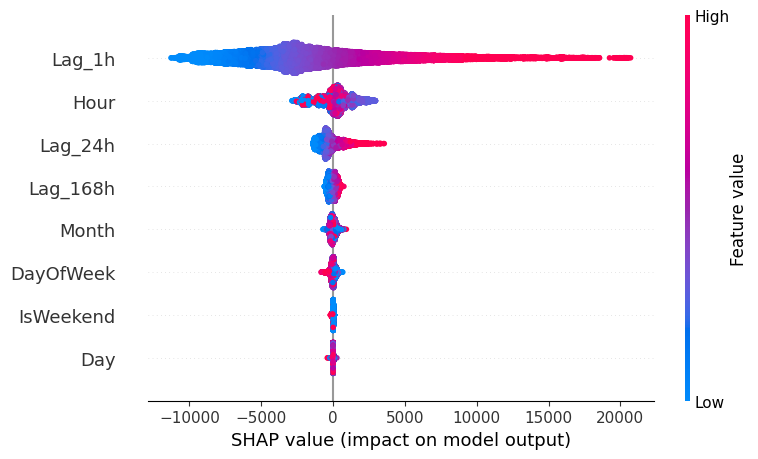

In [207]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=True)

--- Prediction 1 ---
Actual: 29685.00 MW, Predicted: 29847.87 MW


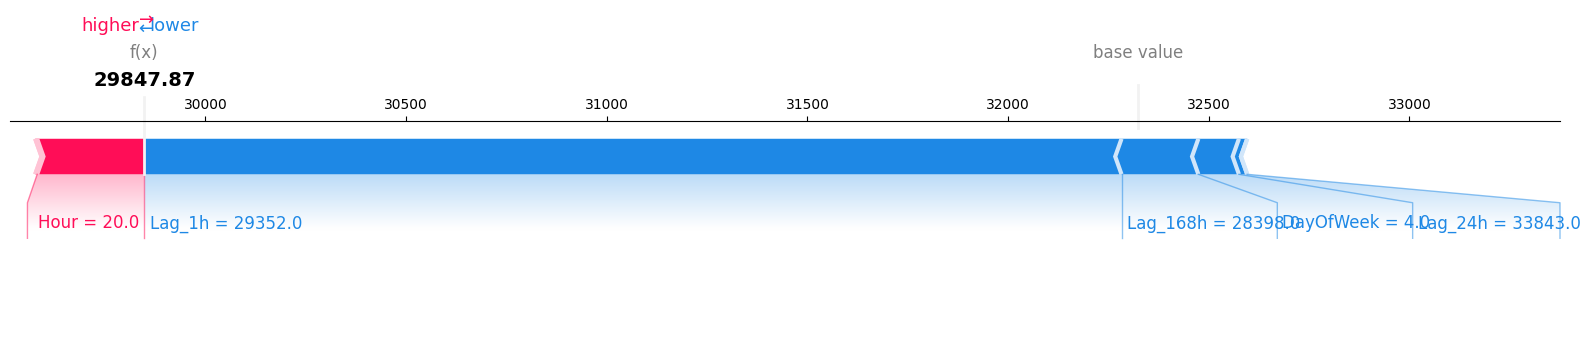

--- Prediction 2 ---
Actual: 30185.00 MW, Predicted: 30312.45 MW


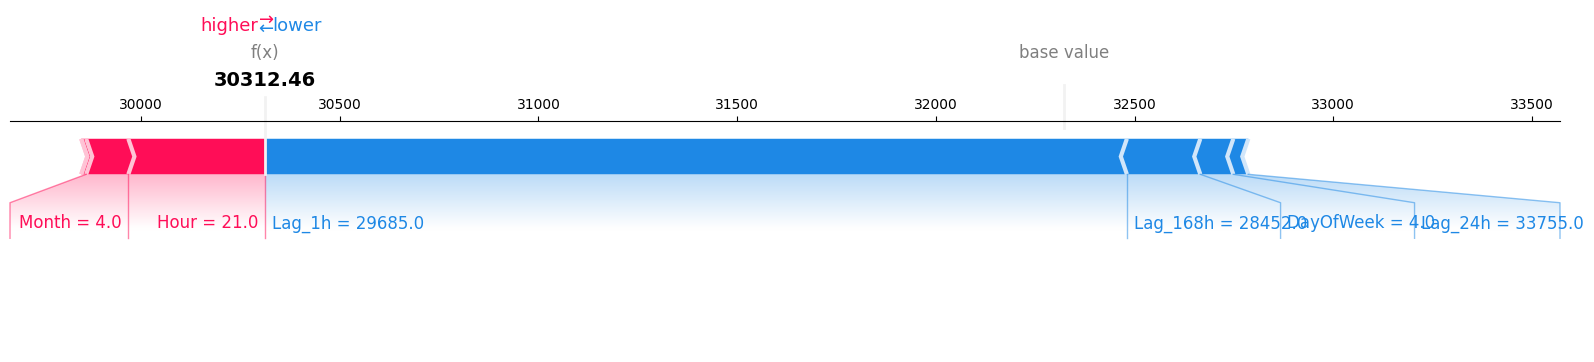

--- Prediction 3 ---
Actual: 29187.00 MW, Predicted: 29504.43 MW


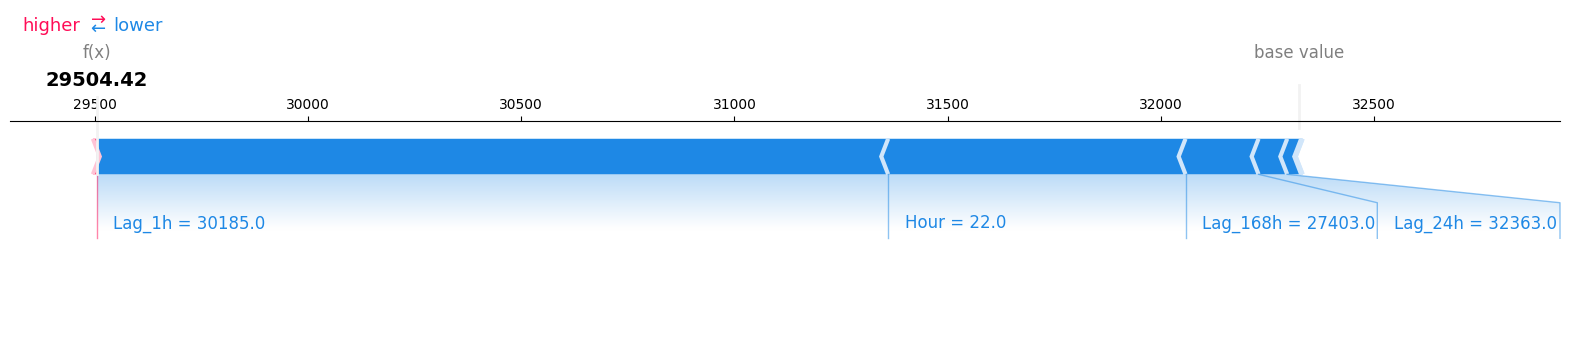

In [208]:
for i in range(3):
  print(f"--- Prediction {i+1} ---")
  print(f"Actual: {y_test.iloc[i]:.2f} MW, Predicted: {y_pred[i]:.2f} MW")
  shap.force_plot(explainer.expected_value, shap_values[i], X_test.iloc[i], matplotlib=True, show=True)

## LIME for LSTM Model

In [227]:
!pip install lime -q
from lime import lime_tabular

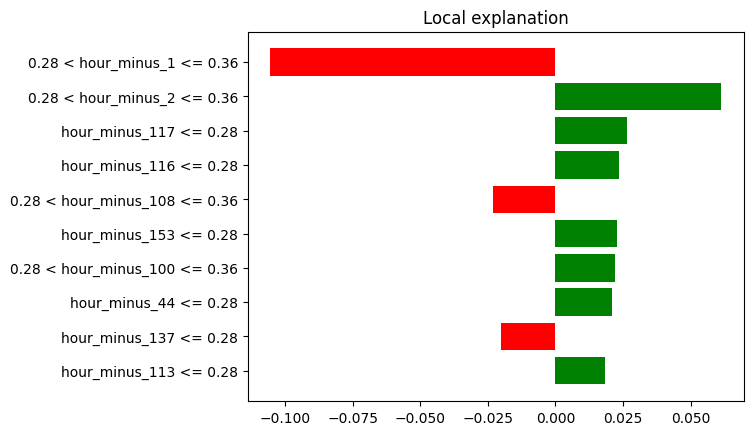

In [228]:
X_train_flat = X_train_lstm.reshape(X_train_lstm.shape[0], -1)
X_test_flat = X_test_lstm.reshape(X_test_lstm.shape[0], -1)

lime_explainer = lime_tabular.LimeTabularExplainer(
    X_train_flat,
    mode='regression',
    feature_names=[f"hour_minus_{window_size-i}" for i in range(window_size)],
    random_state=42
)

exp = lime_explainer.explain_instance(
    X_test_flat[0],
    lambda x: lstm_model.predict(x.reshape(-1, window_size, 1), verbose=0).flatten(),
    num_features=10
)
exp.as_pyplot_figure();

--- LSTM Prediction 1 ---


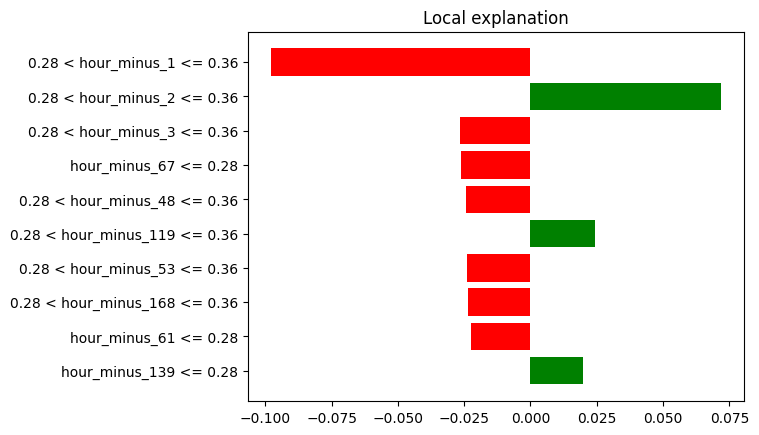

--- LSTM Prediction 2 ---


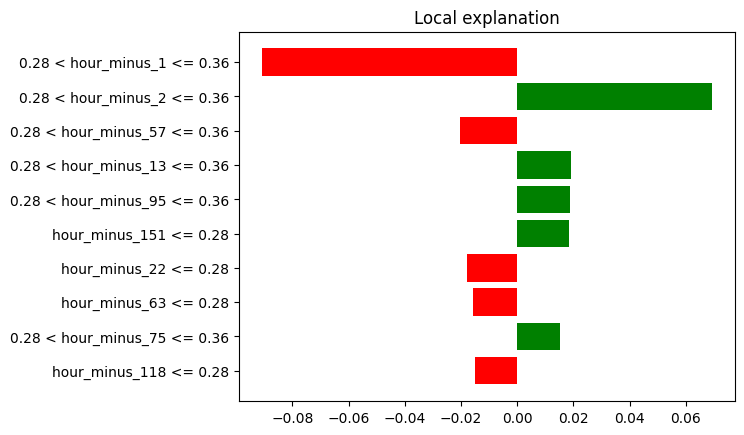

--- LSTM Prediction 3 ---


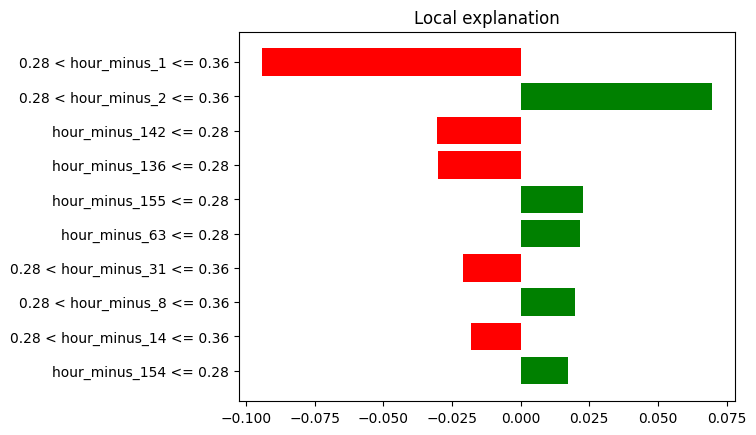

In [229]:
import matplotlib.pyplot as plt

for i in range(3):
  print(f"--- LSTM Prediction {i+1} ---")
  exp = lime_explainer.explain_instance(
      X_test_flat[i],
      lambda x: lstm_model.predict(x.reshape(-1, window_size, 1), verbose=0).flatten(),
      num_features=10
  )
  exp.as_pyplot_figure()
  plt.show()

## Temporal Attribution (aggregated LIME)

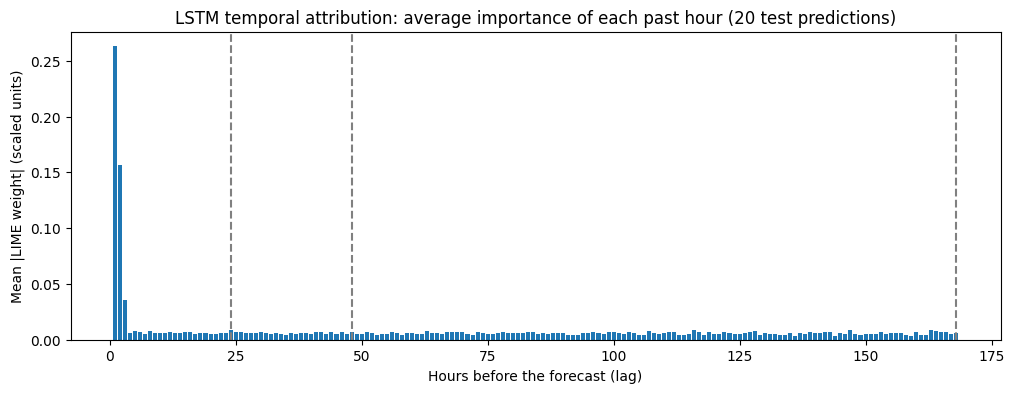

Top 10 lags: [1, 2, 3, 147, 24, 116, 163, 5, 107, 164]


In [230]:
import matplotlib.pyplot as plt

lime_explainer = lime_tabular.LimeTabularExplainer(
    X_train_flat,
    mode='regression',
    feature_names=[f"hour_minus_{window_size-i}" for i in range(window_size)],
    random_state=42
)
predict_fn = lambda x: lstm_model.predict(x.reshape(-1, window_size, 1), verbose=0).flatten()

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_test_flat), 20, replace=False)   # 20 random test predictions

importance = np.zeros(window_size)
for j in sample_idx:
    exp = lime_explainer.explain_instance(X_test_flat[j], predict_fn, num_features=window_size)
    for feat, w in exp.as_map()[1]:
        importance[feat] += abs(w)
importance /= len(sample_idx)

lags = window_size - np.arange(window_size)          # column i = hour_minus_(168 - i)
plt.figure(figsize=(12, 4))
plt.bar(lags, importance)
for lag in [24, 48, 168]:
    plt.axvline(lag, linestyle='--', color='grey')
plt.xlabel('Hours before the forecast (lag)')
plt.ylabel('Mean |LIME weight| (scaled units)')
plt.title('LSTM temporal attribution: average importance of each past hour (20 test predictions)')
plt.show()

top = np.argsort(importance)[::-1][:10]
print("Top 10 lags:", [int(lags[k]) for k in top])

## Interpretability Results

**XGBoost (SHAP).** Lag_1h (the previous hour's demand) is by far the most influential feature, followed by Hour, Lag_24h and Lag_168h. High recent demand pushes the forecast up and low recent demand pushes it down.

**LSTM (LIME, individual predictions).** For each of the three explained predictions, hour_minus_1 and hour_minus_2 had the largest weights. These two features often received opposite signs, which may indicate that the model responds to the short-term trend between the last two hours. However, this should be interpreted with caution (see limitations below).

**LSTM (temporal attribution, 20 test predictions).** Averaging absolute LIME weights across 20 randomly selected test predictions shows that importance is concentrated in the last three hours and decreases sharply after that (top lags: 1, 2, 3, then 147 and 24). The 24-hour lag is among the top five but only slightly above the background level, suggesting at most a weak daily pattern, and no clear weekly (168-hour) peak was found.

**Agreement between methods.** Both SHAP (XGBoost) and LIME (LSTM) identify the most recent demand as the dominant driver of the forecast, and both show a smaller daily (24-hour) effect.

**Limitations.** (1) Neighbouring hours are highly correlated, but LIME perturbs each feature independently, which can split or reverse the weights of similar features. (2) LIME results vary between runs; a fixed random_state was used for the temporal attribution to make it reproducible. (3) LIME weights are in scaled units, not MW. (4) The temporal attribution is based on 20 predictions, so small differences between lags should not be over-interpreted.

**In plain English:** both models mainly predict the next hour from what happened in the last one to three hours, with a smaller influence from the same time on the previous day.

In [213]:
print("Test period:", test['Datetime'].min(), "to", test['Datetime'].max())
print("Average demand in test period:", round(test['PJME_MW'].mean()), "MW")

Test period: 2015-04-10 20:00:00 to 2018-08-03 00:00:00
Average demand in test period: 31090 MW
